In [1]:
%load_ext autoreload
%autoreload 2

# Classification models

Here, we run all our classification models so that we can compare them side-by-side. We compare a dummy model and simple logistic model to logistic models with two reguralization strategies (L1 and L2), a decision tree model, a random forest model, and a boosted regression tree model. Hyperparameters are tuned using either GridSearchCV or RandomizedSearchCV. We also run our models on several different splits to understand the limits of our models.

In [2]:
'''Import all relevant modules here and define root directory.'''

# Define root directory
import sys
from pathlib import Path

cwd = Path.cwd()
ROOT = next(p for p in [cwd, *cwd.parents] if (p / ".git").exists())
sys.path.insert(0, str(ROOT))

# Modules imported form outside
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.calibration import calibration_curve

# Modules internal to this project
from src.models.evaluate import CONFIGS, run_models, tuned, all_features, linear_features, load_predictions
from src.evaluation.results_log import load_runs, summarize

The following cell is used to set up necessary variables and define the parameter grids used for hyperparameter tuning.

In [3]:
BRIER = "neg_brier_score"                       # tune for well-calibrated probabilities
C_VALUES = np.logspace(-4, 2, 13)
TREE_DEPTHS = [2, 3, 4, 5, 6, 8, 10, 15]
RF_GRID = {
    "max_depth": [6, 8, 11, 15, None], 
    "max_features": ["sqrt", 0.3, 0.5], 
    "min_samples_leaf": [1, 5, 20]
}
BRT_GRID = {
    "learning_rate": [0.03, 0.05], 
    "n_estimators": [20, 35, 50, 75, 100], 
    "max_depth": [2, 3, 4], 
    "min_child_weight": [5, 20, 50], 
    "subsample": [0.5, 0.7]
}

In [4]:
def linear_pipe(model):
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), model)

The following cell contains our list of classification models.

In [5]:
CLASSIFICATION_MODELS = {
    "Dummy (prior)": ("Team", lambda: DummyClassifier(strategy="prior"), all_features),
    "Logistic": ("Andrea", lambda: linear_pipe(LogisticRegression(C=np.inf, max_iter=5000)), linear_features),
    "Logistic L2": ("Andrea", lambda: tuned(linear_pipe(LogisticRegression(max_iter=5000)), {"logisticregression__C": C_VALUES}, BRIER), linear_features),
    "Logistic L1": ("Andrea", lambda: tuned(linear_pipe(LogisticRegression(l1_ratio=1, solver="liblinear", max_iter=5000)), {"logisticregression__C": C_VALUES}, BRIER), linear_features),
    "Decision tree": ("Gavin", lambda: tuned(DecisionTreeClassifier(min_samples_leaf=20, random_state=0), {"max_depth": TREE_DEPTHS}, BRIER), all_features),
    "Random forest": ("Charlsey", lambda: tuned(RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=1), RF_GRID, BRIER, n_iter=10), all_features),
    "XGBoost BRT": ("Karuna", lambda: tuned(xgboost.XGBClassifier(objective="binary:logistic", max_bin=64, random_state=0, n_jobs=1), BRT_GRID, BRIER, n_iter=20), all_features),
}

In [6]:
'''Run all models on each of the splits/configurations. The last fold in each split is set aside in each case for final validation.'''

RUN_MODELS = False    # True: refit every model (about 20 minutes per notebook); False: load the saved predictions

if RUN_MODELS:
    devs, oof = run_models(CLASSIFICATION_MODELS, task="classification")
else:
    devs, oof = load_predictions("classification")

We now compare model performances across all configurations.

In [7]:
clf_runs = load_runs().query("task == 'classification'")
for metric in ["brier_skill", "auc"]:
    display(clf_runs.groupby(["model", "split", "use_subbasin"])[metric].mean().unstack(["split", "use_subbasin"]).round(3))

split           10km        10km_subbasin 5km_subbasin 7.5km_subbasin
use_subbasin   False  True          True         True           True 
model                                                                
Decision tree  0.103  0.188         0.211        0.180          0.197
Dummy (prior)  0.000  0.000         0.000        0.000          0.000
Logistic       0.091  0.150         0.225        0.218          0.197
Logistic L1    0.122  0.191         0.228        0.219          0.228
Logistic L2    0.135  0.195         0.206        0.216          0.220
Random forest  0.225  0.242         0.291        0.265          0.254
XGBoost BRT    0.216  0.216         0.272        0.246          0.244

split           10km        10km_subbasin 5km_subbasin 7.5km_subbasin
use_subbasin   False  True          True         True           True 
model                                                                
Decision tree  0.713  0.762         0.765        0.771          0.743
Dummy (prior)  0.500  0.500         0.500        0.500          0.500
Logistic       0.735  0.771         0.800        0.798          0.769
Logistic L1    0.734  0.787         0.798        0.795          0.786
Logistic L2    0.738  0.787         0.791        0.792          0.778
Random forest  0.791  0.801         0.827        0.826          0.796
XGBoost BRT    0.791  0.794         0.809        0.811          0.790

See model performance on the main configuration: 10km grid cells stratified along subbasin, with subbasin data included as a feature.

In [8]:
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay, average_precision_score, precision_score, recall_score, f1_score, balanced_accuracy_score, brier_score_loss)

CONFIG = ("10km_subbasin", True)      # which configuration to plot
THRESHOLD = 0.5                       # probability at or above which a sample is called an exceedance
FIGURES = ROOT / "results" / "classification"
FIGURES.mkdir(parents=True, exist_ok=True)

dev = devs[CONFIG]
y_true = dev["exceeds"].to_numpy()
folds = dev["fold"].to_numpy()
prevalence = y_true.mean()
probs = {name: oof[(name, *CONFIG)] for name in CLASSIFICATION_MODELS if not name.startswith("Dummy")}
TAG = f"{CONFIG[0]}, subbasin features={CONFIG[1]}"


def panels(n, ncols=3, width=4.5, height=3.8):
    """A grid with one panel per model (or metric); unused panels are hidden."""
    nrows = -(-n // ncols)                            # ceiling division
    fig, axs = plt.subplots(nrows, ncols, figsize=(width * ncols, height * nrows), squeeze=False)
    axs = axs.ravel()
    for ax in axs[n:]:
        ax.set_axis_off()
    return fig, axs


def save(fig, name):
    fig.savefig(FIGURES / f"{name}_{CONFIG[0]}_subbasin{int(CONFIG[1])}.png", dpi=150, bbox_inches="tight")


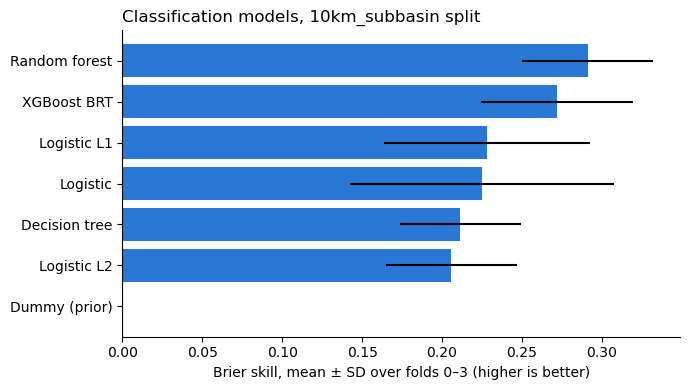

In [9]:
main = clf_runs[(clf_runs["split"] == CONFIG[0]) & (clf_runs["use_subbasin"] == CONFIG[1])]
by_model = main.groupby("model")["brier_skill"].agg(["mean", "std"]).sort_values("mean", ascending=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(by_model.index, by_model["mean"], xerr=by_model["std"], color="#2a78d6")
ax.invert_yaxis()                                   # best model on top
ax.axvline(0, color="gray", linewidth=0.8)          # 0 = no better than the training exceedance rate
ax.set_xlabel("Brier skill, mean ± SD over folds 0–3 (higher is better)")
ax.set_title(f"Classification models, {CONFIG[0]} split", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
save(fig, "model_comparison")
plt.show()


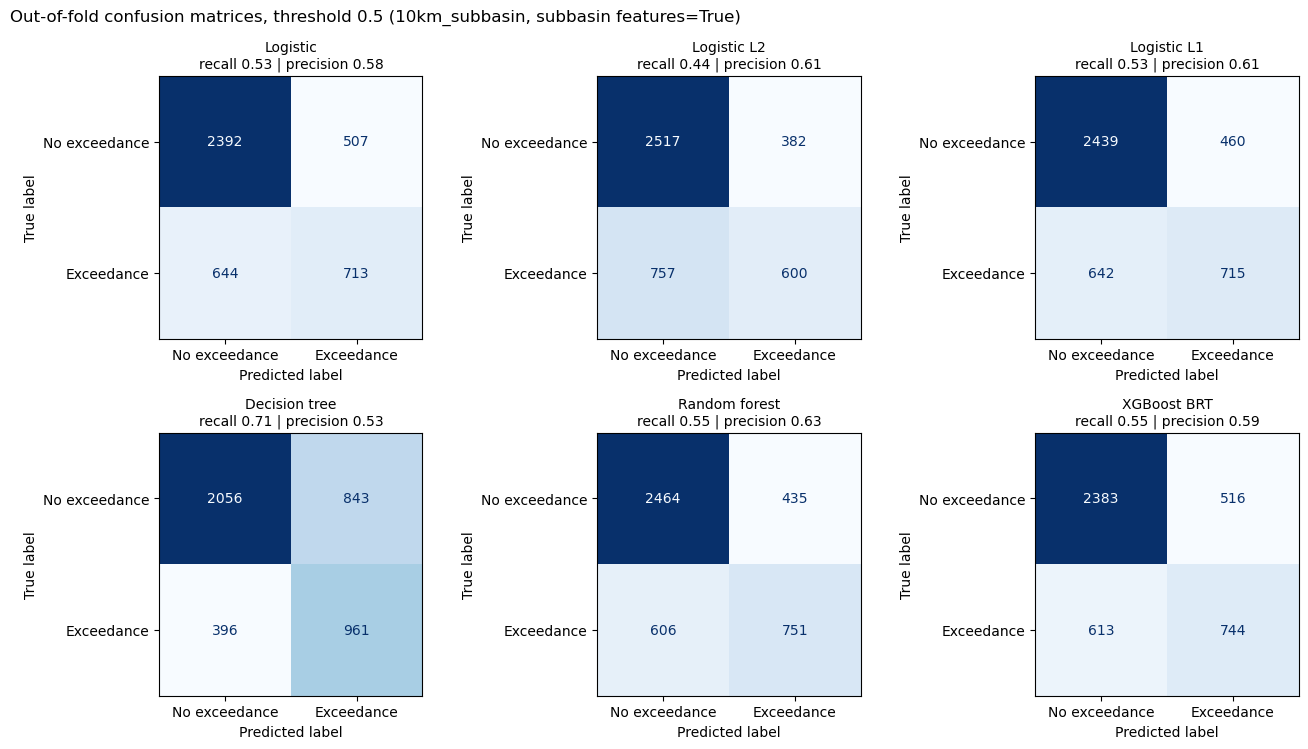

In [10]:
fig, axs = panels(len(probs))
for ax, (name, prob) in zip(axs, probs.items()):
    predicted = (prob >= THRESHOLD).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y_true, predicted, labels=[0, 1], display_labels=["No exceedance", "Exceedance"],
        cmap="Blues", values_format="d", colorbar=False, ax=ax)
    ax.set_title(f"{name}\nrecall {recall_score(y_true, predicted):.2f} | "
                 f"precision {precision_score(y_true, predicted, zero_division=0):.2f}", fontsize=10)
fig.suptitle(f"Out-of-fold confusion matrices, threshold {THRESHOLD} ({TAG})", x=0.01, ha="left")
plt.tight_layout()
save(fig, "confusion_matrices")
plt.show()


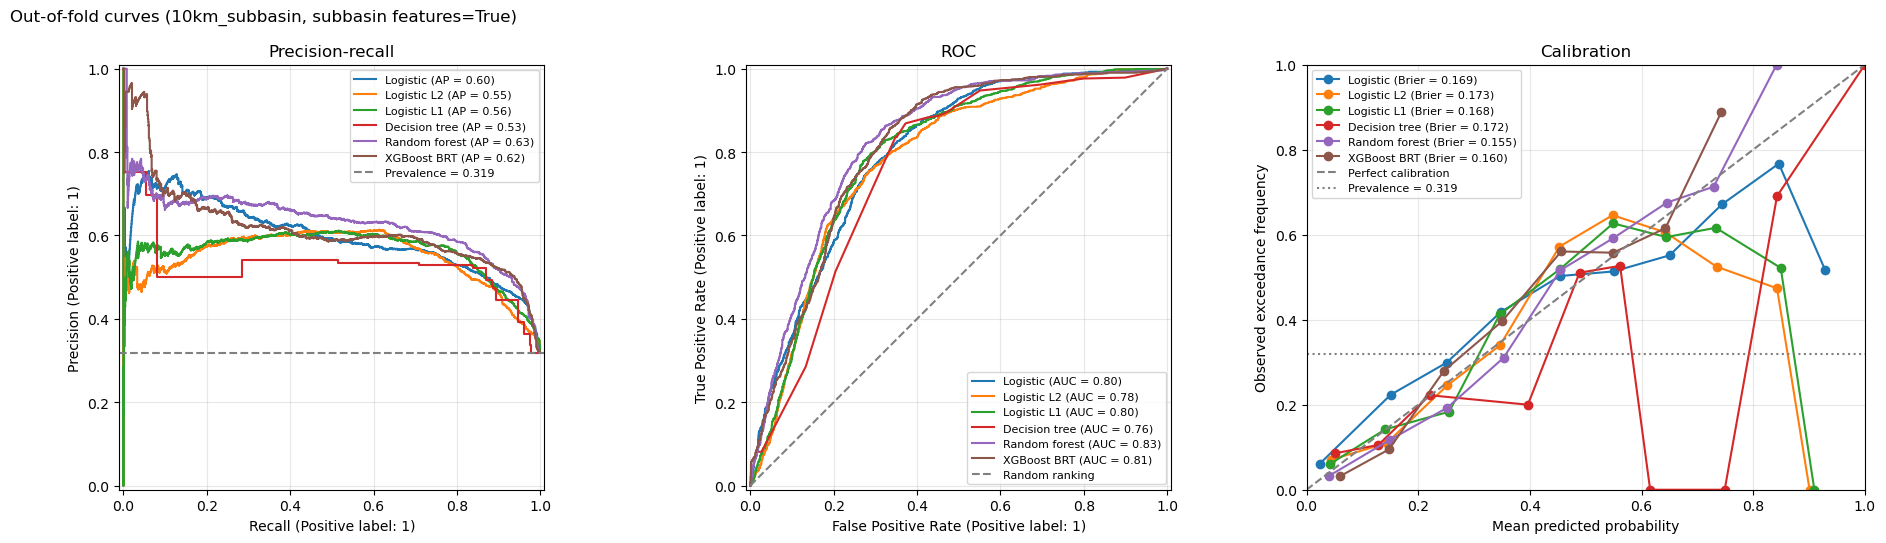

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(19, 5.5))
for name, prob in probs.items():
    PrecisionRecallDisplay.from_predictions(y_true, prob, name=name, ax=axs[0])
    RocCurveDisplay.from_predictions(y_true, prob, name=name, ax=axs[1])
    observed, predicted = calibration_curve(y_true, prob, n_bins=10, strategy="uniform")
    axs[2].plot(predicted, observed, marker="o", label=f"{name} (Brier = {brier_score_loss(y_true, prob):.3f})")

axs[0].axhline(prevalence, color="gray", linestyle="--", label=f"Prevalence = {prevalence:.3f}")
axs[0].set_title("Precision-recall")
axs[1].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random ranking")
axs[1].set_title("ROC")
axs[2].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Perfect calibration")
axs[2].axhline(prevalence, color="gray", linestyle=":", label=f"Prevalence = {prevalence:.3f}")
axs[2].set(xlim=(0, 1), ylim=(0, 1), xlabel="Mean predicted probability", ylabel="Observed exceedance frequency", title="Calibration")
for ax in axs:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
fig.suptitle(f"Out-of-fold curves ({TAG})", x=0.01, ha="left")
plt.tight_layout()
save(fig, "pr_roc_calibration")
plt.show()


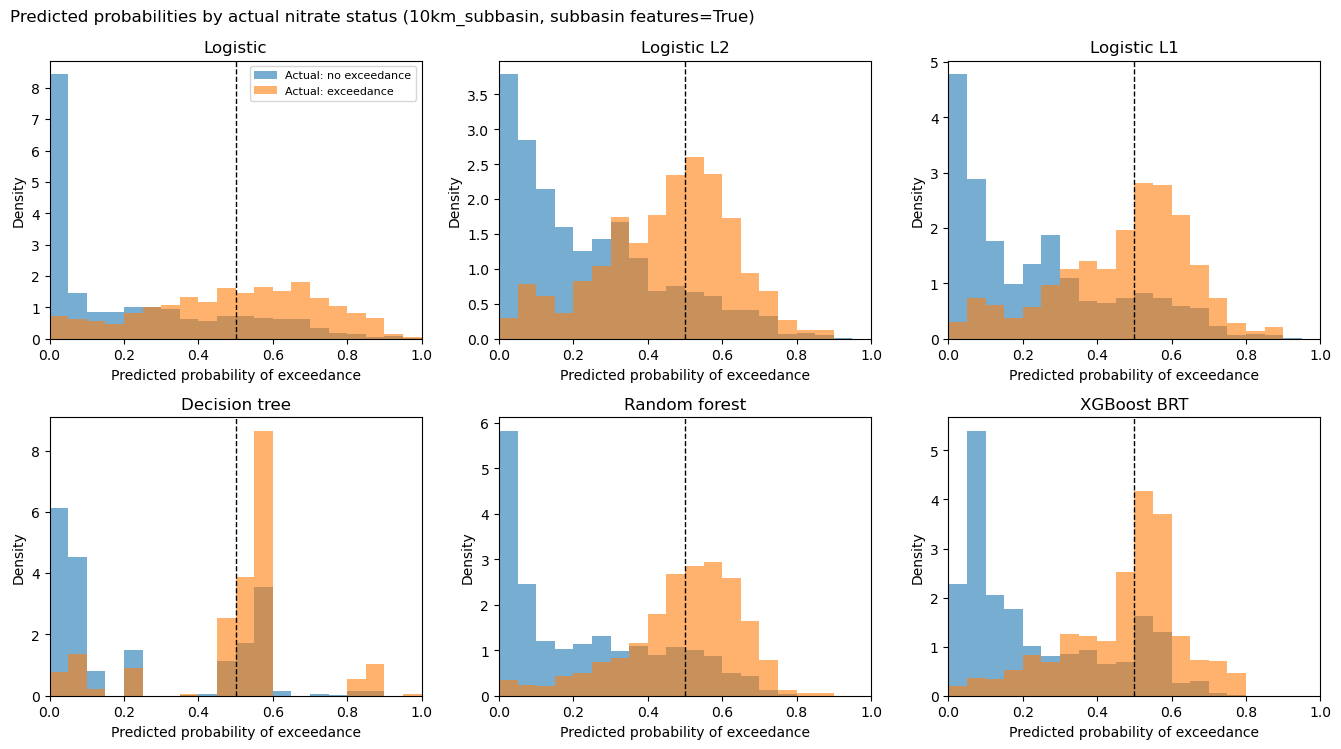

In [12]:
fig, axs = panels(len(probs))
for ax, (name, prob) in zip(axs, probs.items()):
    ax.hist(prob[y_true == 0], bins=20, range=(0, 1), alpha=0.6, density=True, label="Actual: no exceedance")
    ax.hist(prob[y_true == 1], bins=20, range=(0, 1), alpha=0.6, density=True, label="Actual: exceedance")
    ax.axvline(THRESHOLD, color="black", linestyle="--", linewidth=1)
    ax.set(title=name, xlabel="Predicted probability of exceedance", ylabel="Density", xlim=(0, 1))
axs[0].legend(fontsize=8)
fig.suptitle(f"Predicted probabilities by actual nitrate status ({TAG})", x=0.01, ha="left")
plt.tight_layout()
save(fig, "probability_distributions")
plt.show()

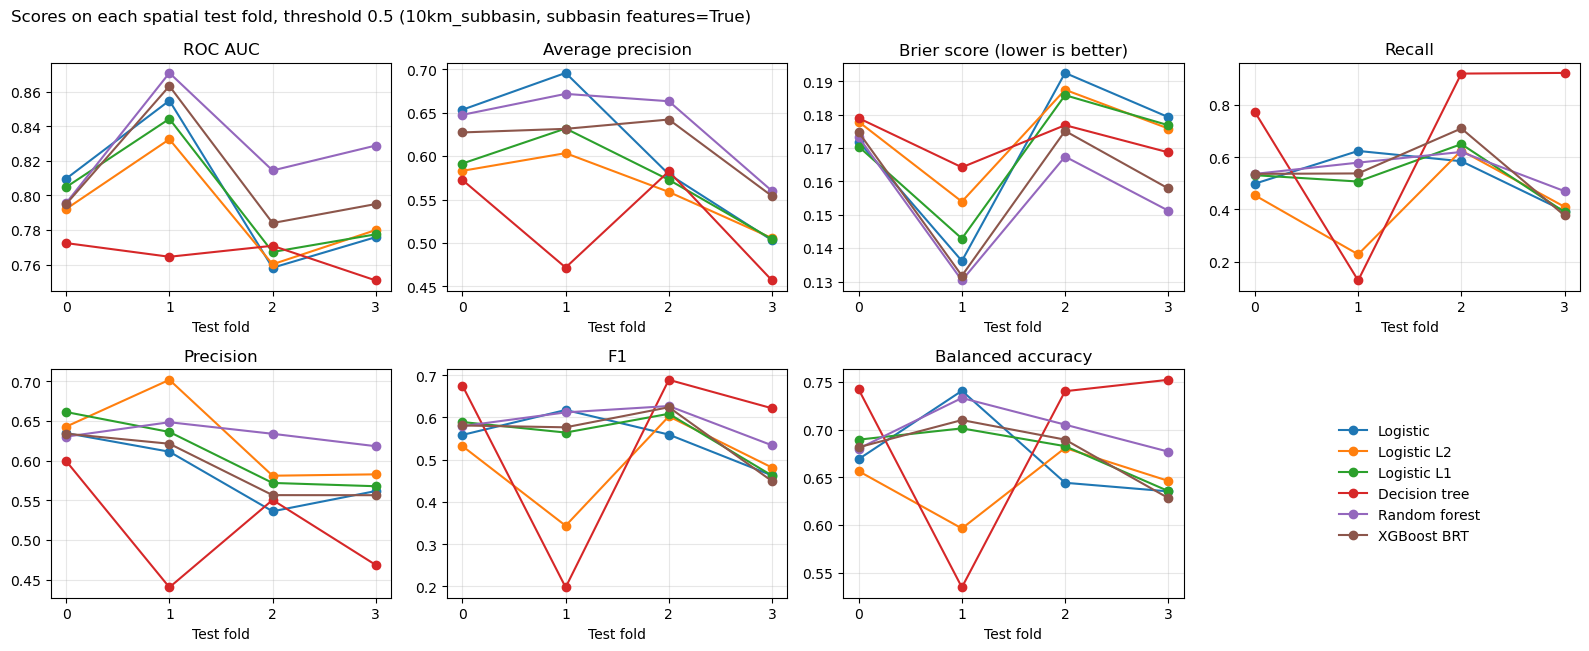

,roc_auc,average_precision,brier_score,recall,precision,f1,balanced_accuracy
model,,,,,,,
Logistic,0.800,0.608,0.170,0.525,0.586,0.550,0.672
Logistic L2,0.791,0.563,0.174,0.429,0.627,0.490,0.645
Logistic L1,0.798,0.575,0.169,0.520,0.609,0.556,0.677
Decision tree,0.765,0.521,0.172,0.686,0.515,0.546,0.692
Random forest,0.827,0.636,0.156,0.551,0.633,0.588,0.699
XGBoost BRT,0.809,0.614,0.160,0.540,0.592,0.558,0.677


In [13]:
rows = []
for name, prob in probs.items():
    for k in np.unique(folds):
        in_fold = folds == k
        actual, p = y_true[in_fold], prob[in_fold]
        predicted = (p >= THRESHOLD).astype(int)
        rows.append({"model": name, "fold": k,
                     "roc_auc": roc_auc_score(actual, p),
                     "average_precision": average_precision_score(actual, p),
                     "brier_score": brier_score_loss(actual, p),
                     "recall": recall_score(actual, predicted, zero_division=0),
                     "precision": precision_score(actual, predicted, zero_division=0),
                     "f1": f1_score(actual, predicted, zero_division=0),
                     "balanced_accuracy": balanced_accuracy_score(actual, predicted)})
fold_metrics = pd.DataFrame(rows)

METRIC_TITLES = {"roc_auc": "ROC AUC", "average_precision": "Average precision",
                 "brier_score": "Brier score (lower is better)", "recall": "Recall",
                 "precision": "Precision", "f1": "F1", "balanced_accuracy": "Balanced accuracy"}

fig, axs = panels(len(METRIC_TITLES), ncols=4, width=4, height=3.3)
for ax, (metric, title) in zip(axs, METRIC_TITLES.items()):
    for name, group in fold_metrics.groupby("model", sort=False):
        ax.plot(group["fold"], group[metric], marker="o", label=name)
    ax.set(title=title, xlabel="Test fold", xticks=np.unique(folds))
    ax.grid(alpha=0.3)
handles, labels = axs[0].get_legend_handles_labels()
axs[len(METRIC_TITLES)].legend(handles, labels, loc="center", frameon=False)   # legend in the spare panel
fig.suptitle(f"Scores on each spatial test fold, threshold {THRESHOLD} ({TAG})", x=0.01, ha="left")
plt.tight_layout()
save(fig, "fold_metrics")
plt.show()

fold_metrics.groupby("model", sort=False).mean(numeric_only=True).drop(columns="fold").round(3)

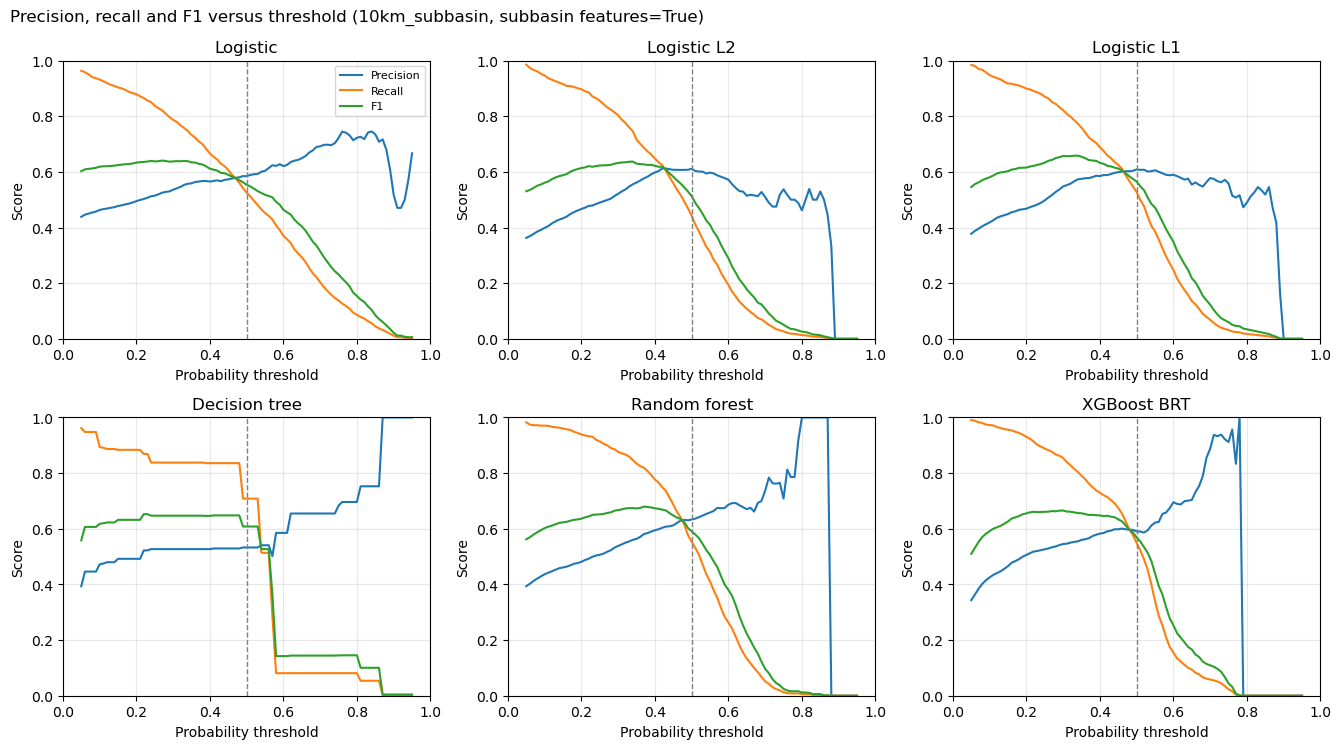

,threshold,precision,recall,f1
model,,,,
Logistic,0.27,0.525,0.821,0.641
Logistic L2,0.34,0.555,0.746,0.637
Logistic L1,0.34,0.573,0.773,0.658
Decision tree,0.22,0.522,0.869,0.652
Random forest,0.37,0.581,0.819,0.680
XGBoost BRT,0.30,0.545,0.854,0.666


In [14]:
thresholds = np.linspace(0.05, 0.95, 91)
fig, axs = panels(len(probs))
best = []
for ax, (name, prob) in zip(axs, probs.items()):
    curve = []
    for t in thresholds:
        predicted = (prob >= t).astype(int)
        curve.append({"threshold": t,
                      "precision": precision_score(y_true, predicted, zero_division=0),
                      "recall": recall_score(y_true, predicted, zero_division=0),
                      "f1": f1_score(y_true, predicted, zero_division=0)})
    curve = pd.DataFrame(curve)
    for col in ["precision", "recall", "f1"]:
        ax.plot(curve["threshold"], curve[col], label=col.capitalize())
    ax.axvline(THRESHOLD, color="gray", linestyle="--", linewidth=1)
    ax.set(title=name, xlabel="Probability threshold", ylabel="Score", xlim=(0, 1), ylim=(0, 1))
    ax.grid(alpha=0.3)
    best.append({"model": name, **curve.loc[curve["f1"].idxmax()].to_dict()})
axs[0].legend(fontsize=8)
fig.suptitle(f"Precision, recall and F1 versus threshold ({TAG})", x=0.01, ha="left")
plt.tight_layout()
save(fig, "threshold_metrics")
plt.show()

pd.DataFrame(best).set_index("model").round(3)      # threshold with the best F1, per model


In [15]:
summarize(load_runs()).to_csv(ROOT / "results" / "model_comparison.csv")